<a href="https://colab.research.google.com/github/francisco-mreina/olist-Predict-Insatisfaction-and-delay/blob/main/05_scoring_vendedores.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis de clientes Olist (Brazilian E-Commerce)

## 8. Scoring y segmentación de actores — Problemas 3 y 4

### 8.1. Scoring de riesgo de vendedores

Para el problema 3 (vendedores de alto riesgo) se construye una **tarjeta de puntuación (*scorecard*)** siguiendo la metodología de tramificación óptima + WOE + regresión logística trabajada en la práctica de Scoring de Minería de Datos (`practica_scoring_P8.ipynb`), con la librería `optbinning`.

A diferencia de los problemas 1 y 2, aquí la unidad de análisis es el **vendedor**, no el pedido, por lo que primero hay que agregar los resultados de cada pedido (retraso, insatisfacción, cancelación) al nivel de `seller_id`, partiendo de `order_items_integrada` (única tabla que conserva `seller_id` junto con el resultado del pedido).

#### Construcción de la tabla de vendedores

In [ ]:
# Reutilizamos las variables objetivo ya definidas en el capítulo 3.3
pedido_targets = pd.DataFrame({
    'order_id': orders_analytical['order_id'],
    'order_status': orders_analytical['order_status'],
    'retraso': retraso.astype(float),
    'insatisfaccion': insatisfaccion.astype(int)
})
pedido_targets['cancelado'] = (pedido_targets['order_status'] == 'canceled').astype(int)

# order_items_integrada es la única tabla a nivel de línea que conserva seller_id
items_vendedor = order_items_integrada[['order_id', 'seller_id', 'price', 'freight_value',
                                          'seller_region']].merge(
    pedido_targets[['order_id', 'retraso', 'insatisfaccion', 'cancelado']],
    on='order_id', how='left'
)

print(items_vendedor.shape)
items_vendedor.head()

(112650, 8)


,order_id,seller_id,price,freight_value,seller_region,retraso,insatisfaccion,cancelado
0,00010242fe8c5a6d1ba2dd792cb16214,48436dade18ac8b2bce089ec2a041202,58.90,13.29,Sudeste,0.0,0,0
1,00018f77f2f0320c557190d7a144bdd3,dd7ddc04e1b6c2c614352b383efe2d36,239.90,19.93,Sudeste,0.0,0,0
2,000229ec398224ef6ca0657da4fc703e,5b51032eddd242adc84c38acab88f23d,199.00,17.87,Sudeste,0.0,0,0
3,00024acbcdf0a6daa1e931b038114c75,9d7a1d34a5052409006425275ba1c2b4,12.99,12.79,Sudeste,0.0,0,0
4,00042b26cf59d7ce69dfabb4e55b4fd9,df560393f3a51e74553ab94004ba5c87,199.90,18.14,Sur,0.0,0,0


In [ ]:
# Agregación a nivel de vendedor
vendedores = items_vendedor.groupby('seller_id').agg(
    n_pedidos=('order_id', 'nunique'),
    tasa_retraso=('retraso', 'mean'),
    tasa_insatisfaccion=('insatisfaccion', 'mean'),
    tasa_cancelacion=('cancelado', 'mean'),
    precio_medio=('price', 'mean'),
    flete_medio=('freight_value', 'mean'),
    seller_region=('seller_region', lambda x: x.mode().iat[0] if not x.mode().empty else np.nan)
).reset_index()

print('Vendedores totales:', vendedores.shape[0])
vendedores['n_pedidos'].describe()

Vendedores totales: 3095


,n_pedidos
count,3095.000000
mean,32.313409
std,105.139763
min,1.000000
25%,2.000000
50%,6.000000
75%,21.500000
max,1854.000000


Como se documentó en el capítulo 2.3, los vendedores están muy concentrados (mediana de 8 pedidos, máximo de más de 2.000), por lo que puntuar a un vendedor con 1 o 2 pedidos totales (de los cuales uno haya ido mal) distorsionaría el modelo. Se aplica un **mínimo de pedidos** antes de entrar en el scoring.

In [ ]:
MIN_PEDIDOS = 5
vendedores_scoring = vendedores[vendedores['n_pedidos'] >= MIN_PEDIDOS].copy()
print(f"Vendedores con >= {MIN_PEDIDOS} pedidos: {vendedores_scoring.shape[0]} de {vendedores.shape[0]}")

# Índice de incidencias: combina las tres tasas de resultado negativo del pedido
vendedores_scoring['indice_incidencias'] = (
    vendedores_scoring['tasa_retraso'] +
    vendedores_scoring['tasa_insatisfaccion'] +
    vendedores_scoring['tasa_cancelacion']
) / 3

#Creamos un umbral de riesgo alto (0.75/1)
umbral_riesgo = vendedores_scoring['indice_incidencias'].quantile(0.75)
vendedores_scoring['alto_riesgo'] = (vendedores_scoring['indice_incidencias'] >= umbral_riesgo).astype(int)

print('Umbral (percentil 75):', round(umbral_riesgo, 4))
print(vendedores_scoring['alto_riesgo'].value_counts(normalize=True))

Vendedores con >= 5 pedidos: 1794 de 3095
Umbral (percentil 75): 0.135
alto_riesgo
0    0.749721
1    0.250279
Name: proportion, dtype: float64


#### División train/test

la partición train/test se hace antes de tramificar: la tramificación óptima y la selección de variables por IV se calculan únicamente sobre el conjunto de entrenamiento, y el conjunto de test se reserva para evaluar el modelo ya ajustado, evitando así sobreajuste en la propia fase de tramificación.

Como predictores del scorecard se usan variables descriptivas del perfil del vendedor (volumen, precio, flete, región)

In [ ]:
Y_completo = vendedores_scoring['alto_riesgo'].values
X_completo = vendedores_scoring[['n_pedidos', 'precio_medio', 'flete_medio', 'seller_region']].copy()

vend_train, vend_test = train_test_split(
    vendedores_scoring, stratify=vendedores_scoring['alto_riesgo'], test_size=0.25, random_state=321
)

Y = vend_train['alto_riesgo'].values
X = vend_train[['n_pedidos', 'precio_medio', 'flete_medio', 'seller_region']].copy()

Y_test = vend_test['alto_riesgo'].values
X_test = vend_test[['n_pedidos', 'precio_medio', 'flete_medio', 'seller_region']].copy()

print('Train:', X.shape, ' Tasa de evento:', Y.mean().round(3))
print('Test :', X_test.shape, ' Tasa de evento:', Y_test.mean().round(3))

Train: (1345, 4)  Tasa de evento: 0.251
Test : (449, 4)  Tasa de evento: 0.249


#### Tramificación óptima, WOE y selección de variables por IV



In [ ]:
list_variables = X.columns.tolist()
list_categorical = X.select_dtypes(include=['object', 'category']).columns.tolist()

selection_criteria = {"iv": {"min": 0.02}}

binning_process_vendedores = BinningProcess(
    min_bin_size=0.10,
    max_n_bins=5,
    categorical_variables=list_categorical,
    variable_names=list_variables,
    selection_criteria=selection_criteria
)

# El propio fit() devuelve el binning_process ya ajustado (patrón habitual de scikit-learn)
binning_process_vendedores.fit(X, Y)

binning_process_vendedores.summary().sort_values('iv', ascending=False)

,name,dtype,status,selected,n_bins,iv,js,gini,quality_score
0,n_pedidos,numerical,OPTIMAL,True,3,0.08687,0.010757,0.145159,0.251074
2,flete_medio,numerical,OPTIMAL,True,4,0.051947,0.00643,0.103531,0.162989
3,seller_region,categorical,OPTIMAL,True,2,0.030381,0.00378,0.06691,0.053133
1,precio_medio,numerical,OPTIMAL,True,5,0.024303,0.003015,0.060825,0.001323


#### Tarjeta de puntuación (Scorecard)

In [ ]:
estimator_vendedores = LogisticRegression(solver='lbfgs', penalty='l2')

pdo_0 = 40
scorecard_points_0 = 600
odds_0_B = 50

scorecard_vendedores = Scorecard(
    binning_process=binning_process_vendedores,
    estimator=estimator_vendedores,
    scaling_method="pdo_odds",
    scaling_method_params={"pdo": pdo_0, "odds": odds_0_B, "scorecard_points": scorecard_points_0}
)
scorecard_vendedores.fit(X, Y, show_digits=4)

scorecard_vendedores.table(style="detailed")

,Variable,Bin id,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS,Coefficient,Points
0,n_pedidos,0,"(-inf, 17.5000)",693,0.515242,489,204,0.294372,-0.221398,0.026617,3.320341e-03,-0.934939,97.362914
1,n_pedidos,1,"[17.5000, 52.5000)",353,0.262454,268,85,0.240793,0.052695,0.000719,8.988431e-05,-0.934939,112.151147
2,n_pedidos,2,"[52.5000, inf)",299,0.222305,251,48,0.160535,0.558611,0.059534,7.346458e-03,-0.934939,139.446993
3,n_pedidos,3,Special,0,0.000000,0,0,0.000000,0.000000,0.000000,0.000000e+00,-0.934939,109.308067
4,n_pedidos,4,Missing,0,0.000000,0,0,0.000000,0.000000,0.000000,0.000000e+00,-0.934939,109.308067
0,precio_medio,0,"(-inf, 69.1938)",438,0.325651,327,111,0.253425,-0.015211,0.000076,9.453441e-06,-0.663948,108.725275
1,precio_medio,1,"[69.1938, 87.0021)",144,0.107063,119,25,0.173611,0.464607,0.020383,2.525210e-03,-0.663948,127.109474
2,precio_medio,2,"[87.0021, 127.2451)",276,0.205204,205,71,0.257246,-0.035310,0.000258,3.226091e-05,-0.663948,107.955149
3,precio_medio,3,"[127.2451, 239.8927)",297,0.220818,220,77,0.259259,-0.045818,0.000469,5.860049e-05,-0.663948,107.552536
4,precio_medio,4,"[239.8927, inf)",190,0.141264,137,53,0.278947,-0.145952,0.003117,3.892964e-04,-0.663948,103.715940


#### Diagnóstico del modelo — conjunto de entrenamiento

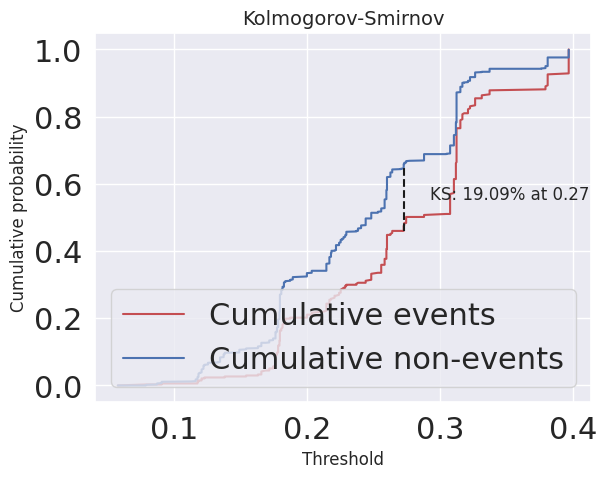

In [ ]:
Y_pred = scorecard_vendedores.predict_proba(X)[:, 1]

# Curva KS, para valorar visualmente la separación entre vendedores de riesgo y el resto
plot_ks(Y, Y_pred)

In [ ]:
# Punto de corte por F1 máximo
c = np.arange(0, 1, 0.01)
f1_scores = [f1_score(Y, np.multiply(Y_pred > c_, 1)) for c_ in c]
c_maxF1 = c[np.argmax(f1_scores)]
print('Punto de corte que maximiza F1:', round(c_maxF1, 2), '| F1 máximo:', round(np.max(f1_scores), 3))

# Punto de corte por índice de Youden
J = [balanced_accuracy_score(Y, np.multiply(Y_pred > c_, 1), adjusted=True) for c_ in c]
c_maxJ = c[np.argmax(J)]
print('Punto de corte que maximiza Youden:', round(c_maxJ, 2), '| J máximo:', round(np.max(J), 3))

# Como en la práctica de referencia, se toma como punto de partida la tasa base de evento
Prob_Corte = Y.mean()
print('Punto de corte adoptado (tasa base):', round(Prob_Corte, 2))

Punto de corte que maximiza F1: 0.25 | F1 máximo: 0.428
Punto de corte que maximiza Youden: 0.27 | J máximo: 0.184
Punto de corte adoptado (tasa base): 0.25


y_pronostico      0      1    All
alto_riesgo                      
0             0.386  0.364  0.749
1             0.083  0.167  0.251
All           0.469  0.531  1.000
Exactitud: 0.553

Sensibilidad (vendedores de riesgo bien detectados): 0.668
Especificidad (vendedores sin riesgo bien detectados): 0.515


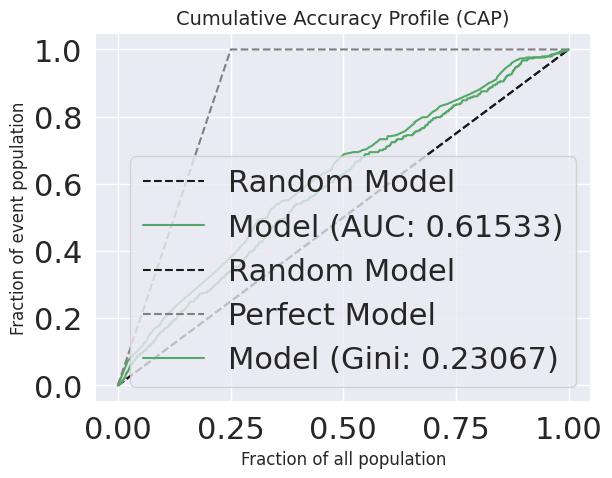

In [ ]:
# Matriz de confusión en entrenamiento con el punto de corte adoptado
vend_train = vend_train.copy()
vend_train['y_pronostico'] = np.multiply(Y_pred > Prob_Corte, 1)

tab = pd.crosstab(vend_train['alto_riesgo'], vend_train['y_pronostico'], margins=True, normalize='all').round(3)
print(tab)
print('Exactitud:', round(tab.iloc[1, 1] + tab.iloc[0, 0], 3))

tab_rec = pd.crosstab(vend_train['alto_riesgo'], vend_train['y_pronostico'], margins=True, normalize=0).round(3)
print('\nSensibilidad (vendedores de riesgo bien detectados):', tab_rec.iloc[1, 1])
print('Especificidad (vendedores sin riesgo bien detectados):', tab_rec.iloc[0, 0])

plot_auc_roc(Y, Y_pred)
plot_cap(Y, Y_pred)

#### Diagnóstico del modelo — conjunto de test (fuera de muestra)

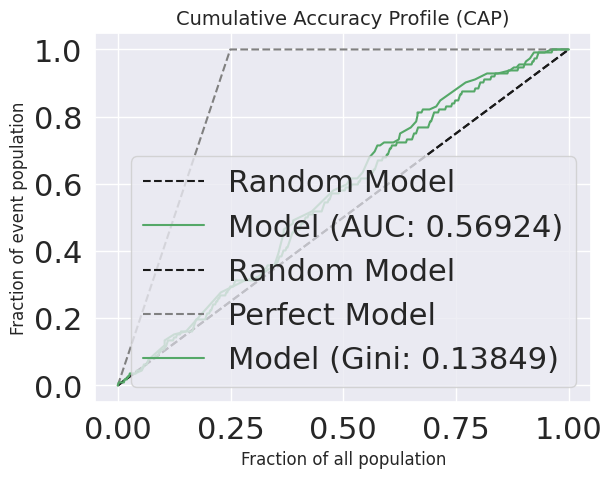

In [ ]:
Y_test_pred = scorecard_vendedores.predict_proba(X_test)[:, 1]

plot_auc_roc(Y_test, Y_test_pred)
plot_cap(Y_test, Y_test_pred)

In [ ]:
vend_test = vend_test.copy()
vend_test['y_pronostico'] = np.multiply(Y_test_pred > Prob_Corte, 1)

print('\nExactitud (test):\n', pd.crosstab(vend_test['alto_riesgo'], vend_test['y_pronostico'],
                                             margins=True, normalize='all').round(3))
print('\nf1-score (test):', round(f1_score(vend_test['alto_riesgo'], vend_test['y_pronostico']), 3))


Exactitud (test):
 y_pronostico      0      1    All
alto_riesgo                      
0             0.363  0.388  0.751
1             0.096  0.154  0.249
All           0.459  0.541  1.000

f1-score (test): 0.389


#### Puntuación final y salida orientada a negocio

Una vez validado el modelo en test, se aplica la tarjeta ya ajustada a **todos** los vendedores con volumen suficiente (train + test) para obtener la puntuación final que alimentará la recomendación del capítulo 11.

In [ ]:
vendedores_scoring['score_riesgo'] = scorecard_vendedores.score(X_completo)
vendedores_scoring['prob_alto_riesgo'] = scorecard_vendedores.predict_proba(X_completo)[:, 1]

print('Puntuación mínima:', round(vendedores_scoring['score_riesgo'].min(), 2))
print('Puntuación máxima:', round(vendedores_scoring['score_riesgo'].max(), 2))
print('Puntuación media :', round(vendedores_scoring['score_riesgo'].mean(), 2))

Puntuación mínima: 398.48
Puntuación máxima: 535.18
Puntuación media : 439.99
